# Solar Energy Adoption Analysis Across U.S. States

Data Source: BigQuery — solar_energy_analysis.v_solar_state_summary

### Project Objective

Analyze solar energy installations across U.S. states, compare
residential and non-residential systems, and explore differences
in state-level solar adoption patterns using BigQuery and Python.

In [3]:
import pandas as pd
from google.cloud import bigquery
import pydata_google_auth

# Authenticate with Google Cloud using your user account
credentials = pydata_google_auth.get_user_credentials(
    scopes=['https://www.googleapis.com/auth/bigquery'],
)

# Initialize the BigQuery client
client = bigquery.Client(
    credentials=credentials,
    project="project-5d6606df-1ef4-4c92-b34"
)

query = """
    SELECT * 
    FROM `project-5d6606df-1ef4-4c92-b34.solar_energy_analysis.v_solar_state_summary`
"""

df = client.query(query).to_dataframe()
df.head()


,state,total_counties,total_tracts,total_systems,residential_systems,nonresidential_systems,total_panel_area,avg_elec_price_residential,avg_incentives_residential,total_population,total_households
0,MN,87,1338,3837.0,2878.0,959.0,0.0,12.00,34.0,5419171,2124745
1,NY,62,4918,60514.0,53144.0,7370.0,0.0,18.54,28.0,19673174,7262279
2,CA,58,8056,693250.0,626966.0,66284.0,0.0,16.99,75.0,38419889,12717383
3,WA,39,1458,12920.0,11568.0,1352.0,0.0,9.00,23.0,6985464,2668912
4,FL,67,4245,155383.0,140265.0,15118.0,0.0,0.58,41.0,19645772,7300494


In [4]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (49, 11)

Columns:
['state', 'total_counties', 'total_tracts', 'total_systems', 'residential_systems', 'nonresidential_systems', 'total_panel_area', 'avg_elec_price_residential', 'avg_incentives_residential', 'total_population', 'total_households']

Missing values:
state                         0
total_counties                0
total_tracts                  0
total_systems                 0
residential_systems           0
nonresidential_systems        0
total_panel_area              0
avg_elec_price_residential    0
avg_incentives_residential    0
total_population              0
total_households              0
dtype: int64

Data types:
state                          object
total_counties                  Int64
total_tracts                    Int64
total_systems                 float64
residential_systems           float64
nonresidential_systems        float64
total_panel_area              float64
avg_elec_price_residential    float64
avg_incentives_residential    float64

In [5]:
# Display all state codes
print(sorted(df["state"].unique()))

# Count unique states
print("Number of unique states:", df["state"].nunique())

# Check for duplicate state codes
print("Duplicate state codes:", df["state"].duplicated().sum())

['AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY']
Number of unique states: 49
Duplicate state codes: 0


### Data Quality Note

The dataset contains 49 state-level records and six columns.
No missing values or duplicate state codes were detected in the
summary view.

However, the absence of missing values does not guarantee data
accuracy. Some residential electricity price values appear
inconsistent and require further validation before they can be
used for reliable comparisons.

In [7]:
# Summary statistics for residential electricity prices
display(df["avg_elec_price_residential"].describe())

# Display the 10 states with the lowest recorded prices
display(
    df.nsmallest(10, "avg_elec_price_residential")[
        ["state", "avg_elec_price_residential"]
    ]
)

# Display the 10 states with the highest recorded prices
display(
    df.nlargest(10, "avg_elec_price_residential")[
        ["state", "avg_elec_price_residential"]
    ]
)

count    49.000000
mean      7.225510
std       7.294382
min       0.130000
25%       0.570000
50%       0.990000
75%      13.640000
max      20.940000
Name: avg_elec_price_residential, dtype: float64

,state,avg_elec_price_residential
41,AZ,0.13
37,OK,0.14
8,MO,0.21
10,KY,0.24
40,MS,0.27
23,NC,0.28
7,LA,0.33
32,KS,0.34
28,VA,0.37
19,NM,0.47


,state,avg_elec_price_residential
38,CT,20.94
18,MA,19.83
48,RI,19.29
1,NY,18.54
34,NH,18.00
42,VT,17.00
2,CA,16.99
27,NJ,15.81
45,ME,15.61
12,MI,14.42


# 1. Top 10 States with the Most Solar Energy Systems

This chart highlights the ten U.S. states with the highest total number of recorded solar energy installations.

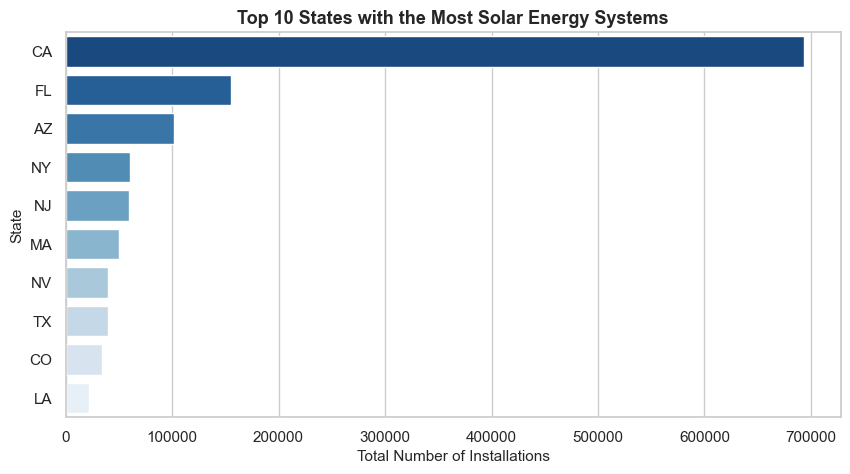

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visualization style
sns.set_theme(style="whitegrid")

# Select the top 10 states by total solar installations
top_10 = df.sort_values(
    by="total_systems",
    ascending=False
).head(10)

# Create the bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_10,
    x="total_systems",
    y="state",
    hue="state",
    palette="Blues_r",
    legend=False
)

# Add chart title and axis labels
plt.title(
    "Top 10 States with the Most Solar Energy Systems",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Total Number of Installations", fontsize=11)
plt.ylabel("State", fontsize=11)

# Save the chart
plt.savefig(
    "../outputs/figures/top_10_solar_states.png",
    bbox_inches="tight",
    dpi=300
)

# Display the chart
plt.show()

### Analysis: Solar Installations by State

This chart compares the ten states with the highest total number
of solar energy installations in the dataset.

California ranks first, followed by Florida and Arizona. The results show that solar installations are unevenly distributed across the states represented in the dataset.

However, installation counts alone do not explain the reasons behind these differences.

# 2. Residential vs. Non-Residential Solar Installations

This chart compares residential and non-residential solar installations across the ten states with the highest total installation counts.

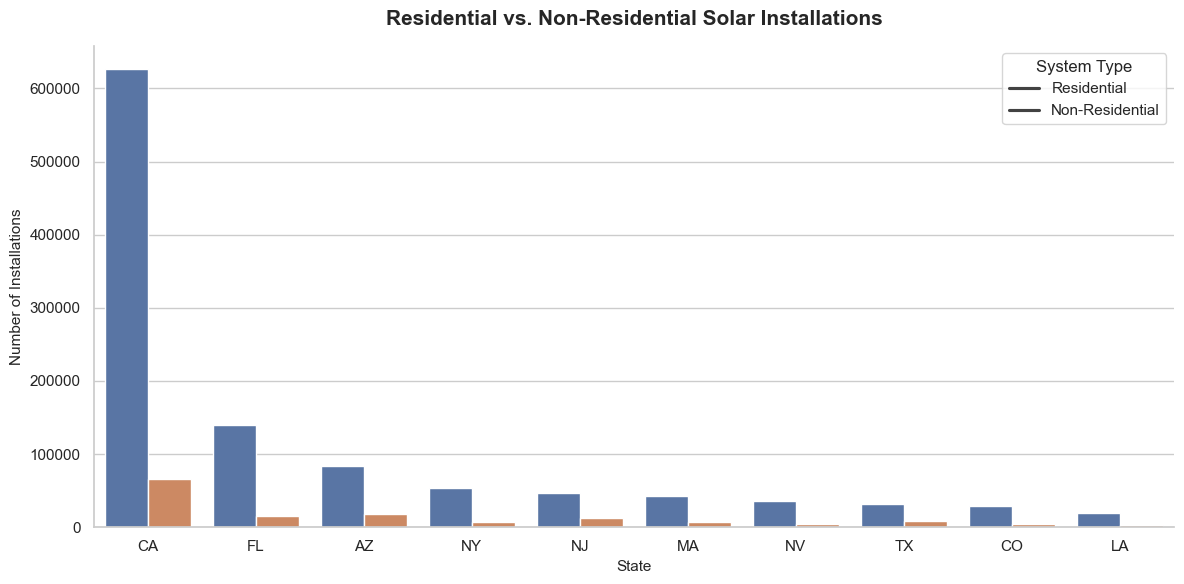

In [12]:
# Set a clean visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Select the top 10 states by total solar installations
top_10 = df.sort_values(
    by="total_systems",
    ascending=False
).head(10)

# Prepare data for the chart
plot_data = top_10.melt(
    id_vars="state",
    value_vars=["residential_systems", "nonresidential_systems"],
    var_name="System Type",
    value_name="Number of Installations"
)

# Create the grouped bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x="state",
    y="Number of Installations",
    hue="System Type"
)

# Add titles and labels
plt.title(
    "Residential vs. Non-Residential Solar Installations",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("State", fontsize=11)
plt.ylabel("Number of Installations", fontsize=11)
plt.legend(
    title="System Type",
    labels=["Residential", "Non-Residential"]
)
sns.despine()
plt.tight_layout()
# Save the figure
plt.savefig(
    "../outputs/figures/residential_vs_non_residential.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

### Analysis: Residential vs. Non-Residential Installations

This chart compares residential and non-residential solar installations across the top 10 states by total installations.

Residential installations make up a larger share in some states, highlighting differences in solar adoption patterns.

# 3. Average Incentives and Solar Installations by State

This section explores the relationship between the incentive measure and total solar installations across U.S. states.

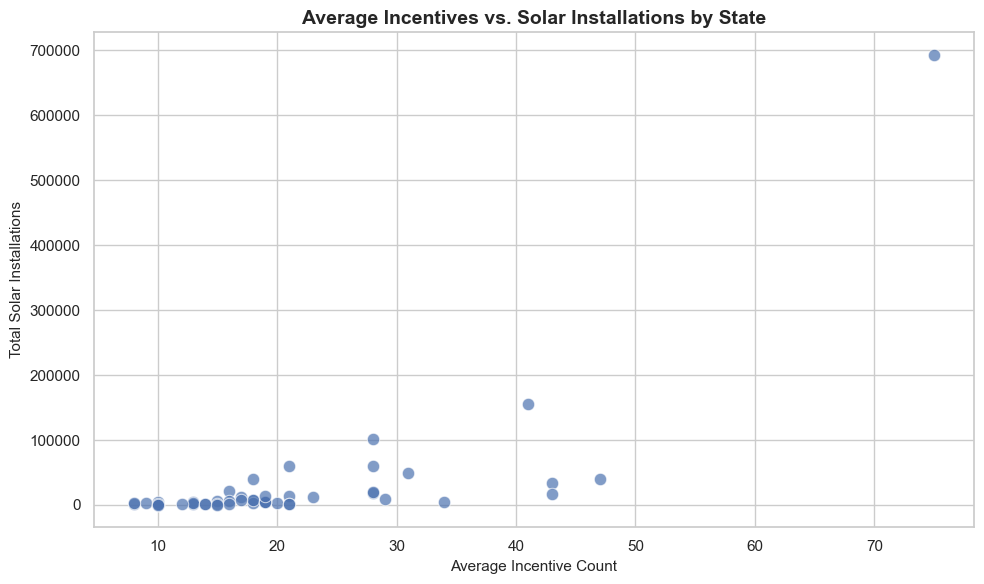

In [17]:
# Analyze the relationship between incentives and solar installations

import matplotlib.pyplot as plt
import seaborn as sns

# Remove rows with missing values in the selected columns
incentive_df = df.dropna(
    subset=["avg_incentives_residential", "total_systems"]
).copy()

# Create the scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=incentive_df,
    x="avg_incentives_residential",
    y="total_systems",
    s=80,
    alpha=0.7
)

plt.title(
    "Average Incentives vs. Solar Installations by State",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average Incentive Count", fontsize=11)
plt.ylabel("Total Solar Installations", fontsize=11)

plt.tight_layout()

# Save the figure
plt.savefig(
    "../outputs/figures/incentives_vs_solar_installations.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

### Analysis: Incentives vs. Solar Installations

This scatter plot explores the relationship between the incentive measure and total solar installations across U.S. states.

California stands out with a high installation count. However, the incentive measure requires further validation, and the chart does not establish a causal relationship between incentives and solar adoption.

# 4. Top Residential Solar Installation Share by State
 Which states have the highest share of residential solar installations?

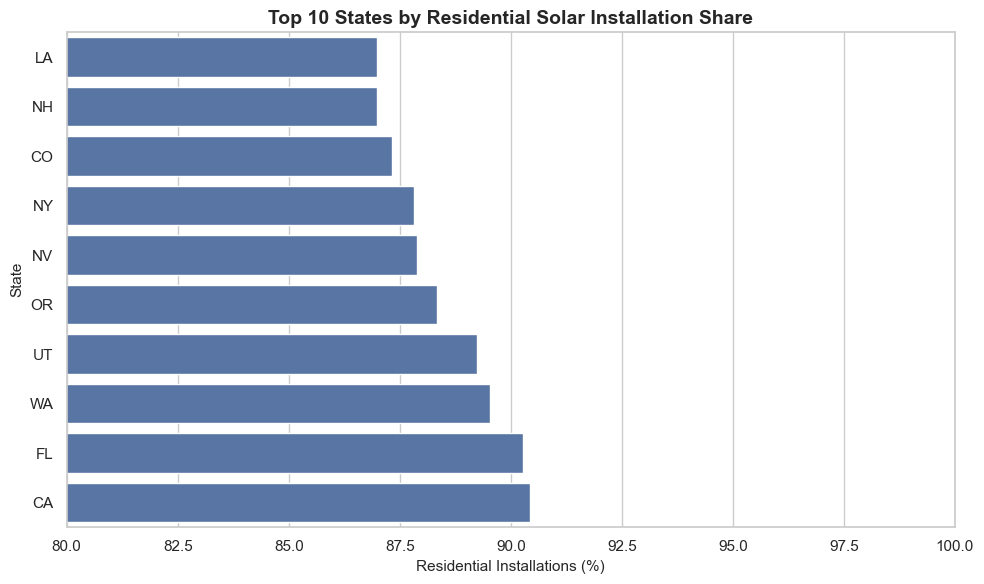

In [19]:
# Calculate the residential share of solar installations
residential_df = df.copy()

residential_df["residential_share_pct"] = (
    residential_df["residential_systems"]
    / residential_df["total_systems"]
) * 100

# Select the 10 states with the highest residential share
top_10_residential = residential_df.nlargest(
    10, "residential_share_pct"
).sort_values("residential_share_pct", ascending=True)

# Create the horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_residential,
    x="residential_share_pct",
    y="state"
)

plt.title(
    "Top 10 States by Residential Solar Installation Share",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Residential Installations (%)", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.xlim(80, 100)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/residential_share_top10.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

### Analysis: Residential Solar Installation Share

This chart compares the residential share of total solar
installations among the ten states with the highest residential
shares in the dataset.

Unlike total installation counts, this percentage shows the
relative contribution of residential systems within each state's
recorded installations.

**Note:** The x-axis starts at 80% to highlight small differences
between states. This truncated axis may make those differences
appear larger than they are in absolute terms.

# Conclusion

## Key Findings

- Solar installations vary considerably across states.
- California has the highest recorded total installation count
  in the analyzed dataset.
- Residential and non-residential installation patterns
  differ across states.
- Residential installation shares provide another perspective
  on state-level solar adoption.

## Limitations

- The source data has not been independently verified.
- Residential electricity price values contain inconsistencies.
- The incentive measure requires further validation.
- The analysis identifies patterns but does not establish
  causal relationships.

In [21]:
print(df.columns.tolist())

['state', 'total_counties', 'total_tracts', 'total_systems', 'residential_systems', 'nonresidential_systems', 'total_panel_area', 'avg_elec_price_residential', 'avg_incentives_residential', 'total_population', 'total_households']


In [23]:
print(df.shape)
print(df.isnull().sum())

(49, 11)
state                         0
total_counties                0
total_tracts                  0
total_systems                 0
residential_systems           0
nonresidential_systems        0
total_panel_area              0
avg_elec_price_residential    0
avg_incentives_residential    0
total_population              0
total_households              0
dtype: int64
